In [190]:
# ===== SEL IDENTITAS - JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo
import sys
import platform
import hashlib
import datetime
import zoneinfo

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

NAMA = 'Nor Rahman Maulana'
NIM = '244107020056' # ganti dengan NIM Anda

N = int(NIM[-3:])

PARAM = {
    'bins' : 2 ** ((N % 4) + 3),
    'clip' : round(1.0 + (N % 5) * 0.5, 1),
    'tile' : (N % 4) + 2,
    'L' : 2 ** ((N % 3) + 1),
}

waktu = datetime.datetime.now(
    zoneinfo.ZoneInfo('Asia/Jakarta')
)

print('NAMA :', NAMA)
print('NIM :', NIM, '| N =', N)

for k, v in PARAM.items():
    print('%-6s :' % k, v)

print('WAKTU :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())

kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')

print(
    'TOKEN :',
    hashlib.sha256(kunci.encode()).hexdigest()[:16]
)

NAMA : Nor Rahman Maulana
NIM : 244107020056 | N = 56
bins   : 8
clip   : 1.5
tile   : 2
L      : 8
WAKTU : 2026-10-02 01:30:25 WIB
SISTEM : 3.14.6 Windows-11-10.0.26200-SP0
TOKEN : ec2540cb0b5503ae


In [191]:
CONTOH = 'Lenna.png'
LENA_LC = 'lena_lc.jpeg'

KTM1A = 'KTM1a.jpeg'
KTM1B = 'KTM1b.jpeg'
KTM1C = 'KTM1c.jpeg'
KTM1D = 'KTM1d.jpeg'


In [192]:
import os

print('=== CEK FILE E-2 ===')

print('Lenna.png :', os.path.exists(CONTOH))
print('lena_lc.jpeg :', os.path.exists(LENA_LC))
print('KTM1a.jpeg :', os.path.exists(KTM1A))
print('KTM1b.jpeg:', os.path.exists(KTM1B))
print('KTM1c.jpeg :', os.path.exists(KTM1C))
print('KTM1d.jpeg :', os.path.exists(KTM1D))


=== CEK FILE E-2 ===
Lenna.png : True
lena_lc.jpeg : True
KTM1a.jpeg : True
KTM1b.jpeg: True
KTM1c.jpeg : True
KTM1d.jpeg : True


In [193]:
def histogram_manual(img, L=256):

    h = np.zeros(
        L,
        dtype=np.int64
    )

    for y in range(img.shape[0]):

        for x in range(img.shape[1]):

            h[img[y, x]] += 1

    return h

In [194]:
def floyd_steinberg(gray, L=2):

    img = gray.astype(
        np.float32
    ).copy()

    step = 255.0 / (L - 1)

    H, W = img.shape

    for y in range(H):

        for x in range(W):

            lama = img[y, x]

            baru = (
                np.round(
                    lama / step
                ) * step
            )

            img[y, x] = baru

            error = lama - baru

            # kanan
            if x + 1 < W:
                img[y, x + 1] += (
                    error * 7 / 16
                )

            # kiri bawah
            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += (
                    error * 3 / 16
                )

            # bawah
            if y + 1 < H:
                img[y + 1, x] += (
                    error * 5 / 16
                )

            # kanan bawah
            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += (
                    error * 1 / 16
                )

    return np.clip(
        img,
        0,
        255
    ).astype(np.uint8)

<BarContainer object of 256 artists>

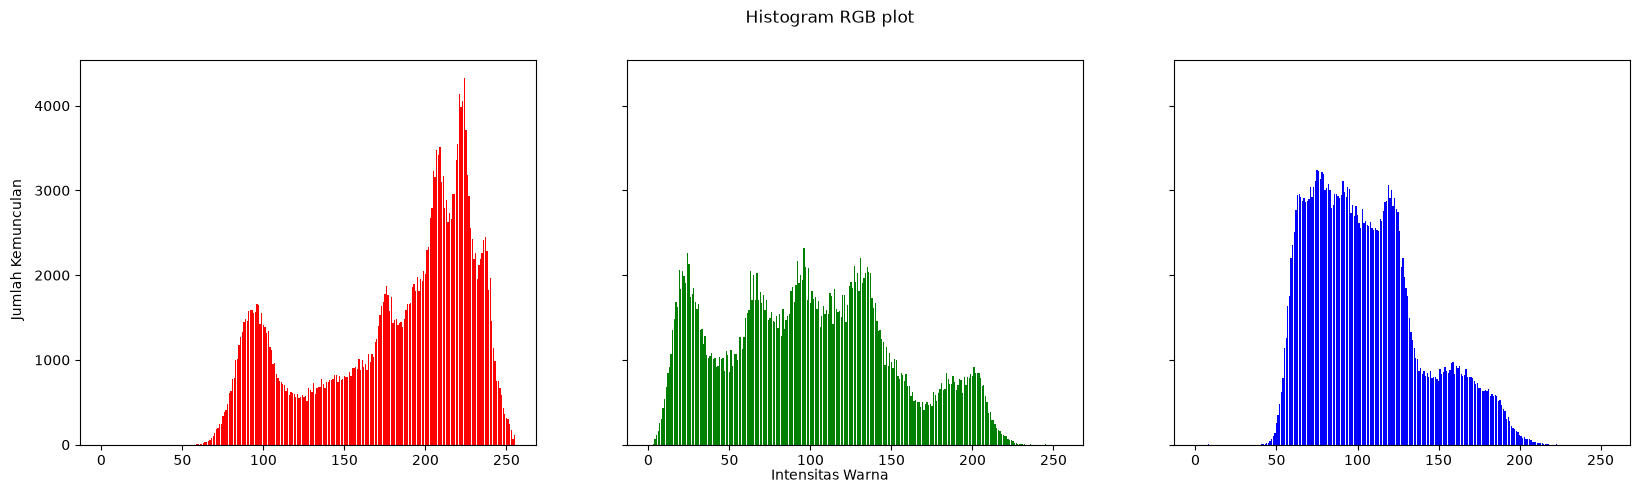

In [195]:
#Membuat histogram image (manual)
img = cv.imread('lenna.png')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)
names = np.arange(256)

red = [0]*256
green = [0]*256
blue = [0]*256

for y in range(0, height):
    for x in range(0, width):
        red[img[y][x][0]] += 1
        green[img[y][x][1]] += 1
        blue[img[y][x][2]] += 1

names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=[20,5], sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')

axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

1. Buatlah histogram citra yang sama menggunakan library NumPy, yaitu numpy.histogram, dan juga cv.calcHist. Bandingkan ketiganya dengan menghitung selisih maksimum antar hasil. Selisihnya harus nol; tampilkan pembuktiannya pada lena.jpg lebih dulu, kemudian ulangi pada KTM1b.jpg.
2. Gambarkan histogram ternormalisasi p(j) dan kurva CDF untuk KTM1a.jpg sampai KTM1d.jpg dalam satu figure 2 x 2. Jelaskan perbedaan bentuk kurva CDF antara citra paling gelap dan citra paling terang milik Anda, lalu kaitkan dengan kondisi pencahayaan saat akuisisi pada Pertemuan 2. 
3. Ulangi histogram KTM1b.jpg dengan jumlah bin sebesar PARAM['bins'] dan dengan 256 bin. Tampilkan keduanya berdampingan dan jelaskan informasi apa yang hilang ketika jumlah bin dikurangi. 

In [196]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt


def read_gray(filename):
    img = cv.imread(filename, cv.IMREAD_GRAYSCALE)

    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {filename}")

    return img

def histogram_manual(img):
    height, width = img.shape

    hist = [0] * 256

    for y in range(height):
        for x in range(width):
            hist[img[y][x]] += 1

    return np.array(hist)

def compare_histograms(filename):

    img = read_gray(filename)
    hist_manual = histogram_manual(img)

    hist_numpy, bins_numpy = np.histogram(
        img.ravel(),
        bins=256,
        range=(0, 256)
    )

    hist_cv = cv.calcHist(
        [img],
        [0],
        None,
        [256],
        [0, 256]
    ).flatten()

    hist_cv = hist_cv.astype(np.int64)

    diff_manual_numpy = np.max(
        np.abs(hist_manual - hist_numpy)
    )

    diff_manual_cv = np.max(
        np.abs(hist_manual - hist_cv)
    )

    diff_numpy_cv = np.max(
        np.abs(hist_numpy - hist_cv)
    )
    max_difference = max(
        diff_manual_numpy,
        diff_manual_cv,
        diff_numpy_cv
    )

    print("=" * 60)
    print(f"PEMBUKTIAN HISTOGRAM : {filename}")
    print("=" * 60)

    print("Selisih Manual vs NumPy      :", diff_manual_numpy)
    print("Selisih Manual vs cv.calcHist:", diff_manual_cv)
    print("Selisih NumPy vs cv.calcHist :", diff_numpy_cv)
    print("Selisih maksimum             :", max_difference)

    if max_difference == 0:
        print("HASIL: KETIGA HISTOGRAM SAMA (SELISIH = 0)")
    else:
        print("HASIL: TERDAPAT PERBEDAAN")

    intensity = np.arange(256)

    plt.figure(figsize=(15, 5))

    plt.plot(
        intensity,
        hist_manual,
        label='Manual'
    )

    plt.plot(
        intensity,
        hist_numpy,
        '--',
        label='NumPy'
    )

    plt.plot(
        intensity,
        hist_cv,
        ':',
        label='cv.calcHist'
    )

    plt.title(f'Perbandingan Histogram - {filename}')
    plt.xlabel('Intensitas')
    plt.ylabel('Jumlah Piksel')
    plt.legend()
    plt.grid()
    plt.show()

    return img, hist_manual, hist_numpy, hist_cv

PEMBUKTIAN HISTOGRAM : lenna.png
Selisih Manual vs NumPy      : 0
Selisih Manual vs cv.calcHist: 0
Selisih NumPy vs cv.calcHist : 0
Selisih maksimum             : 0
HASIL: KETIGA HISTOGRAM SAMA (SELISIH = 0)


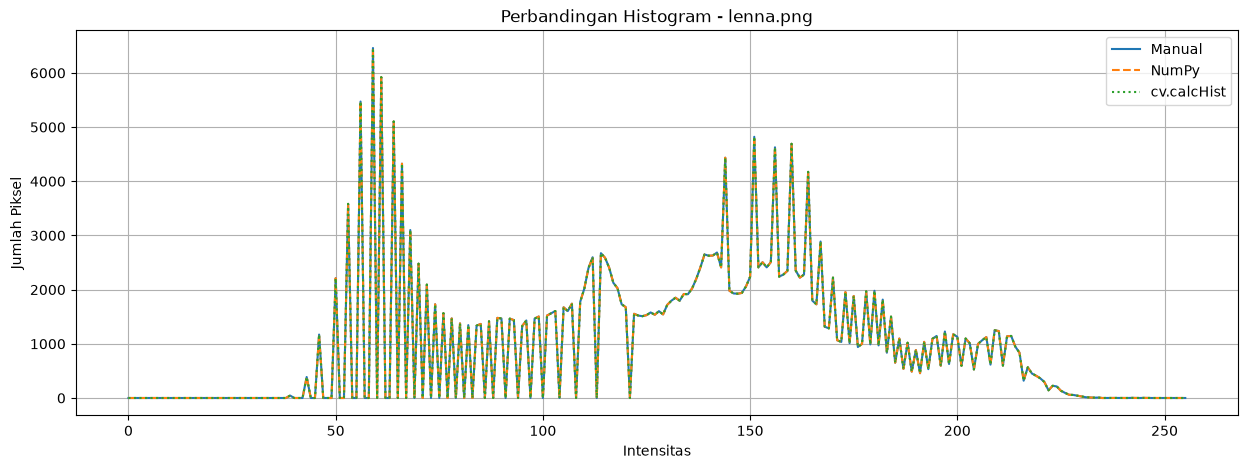

PEMBUKTIAN HISTOGRAM : KTM1b.jpeg
Selisih Manual vs NumPy      : 0
Selisih Manual vs cv.calcHist: 0
Selisih NumPy vs cv.calcHist : 0
Selisih maksimum             : 0
HASIL: KETIGA HISTOGRAM SAMA (SELISIH = 0)


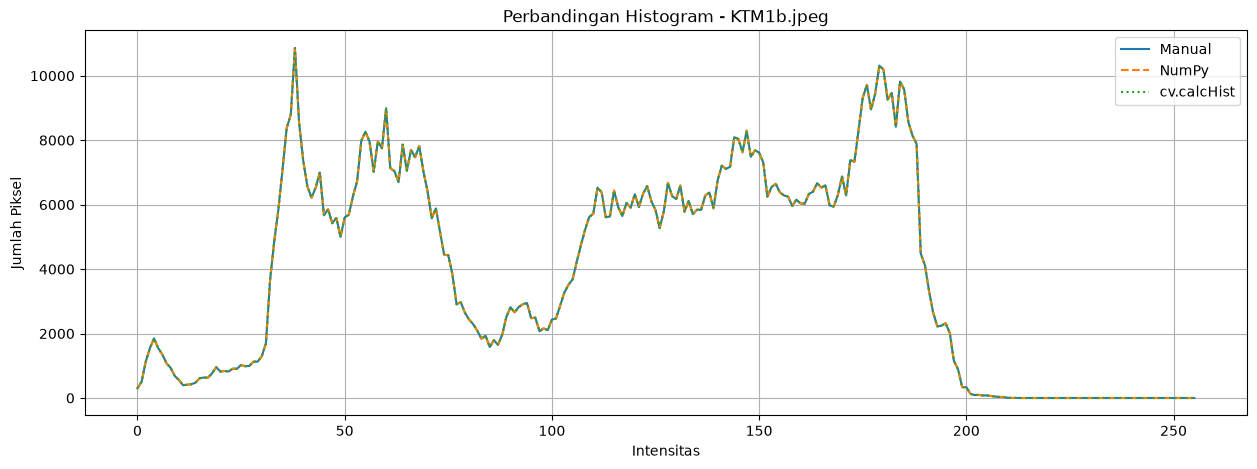

In [197]:
# ============================================================
# NOMOR 1
# Lena.jpg
# ============================================================
img_lena, hist_lena_manual, hist_lena_numpy, hist_lena_cv = \
    compare_histograms('lenna.png')


# ============================================================
# NOMOR 1
# KTM1b.jpg
# ============================================================
img_ktm1b, hist_ktm1b_manual, hist_ktm1b_numpy, hist_ktm1b_cv = \
    compare_histograms('KTM1b.jpeg')


# ============================================================
# FUNGSI HISTOGRAM TERNORMALISASI DAN CDF
# ============================================================
def normalized_histogram_and_cdf(img, bins=256):

    hist, bin_edges = np.histogram(
        img.ravel(),
        bins=bins,
        range=(0, 256)
    )

    # Histogram ternormalisasi p(j)
    p = hist / hist.sum()

    # CDF
    cdf = np.cumsum(p)

    return hist, p, cdf, bin_edges

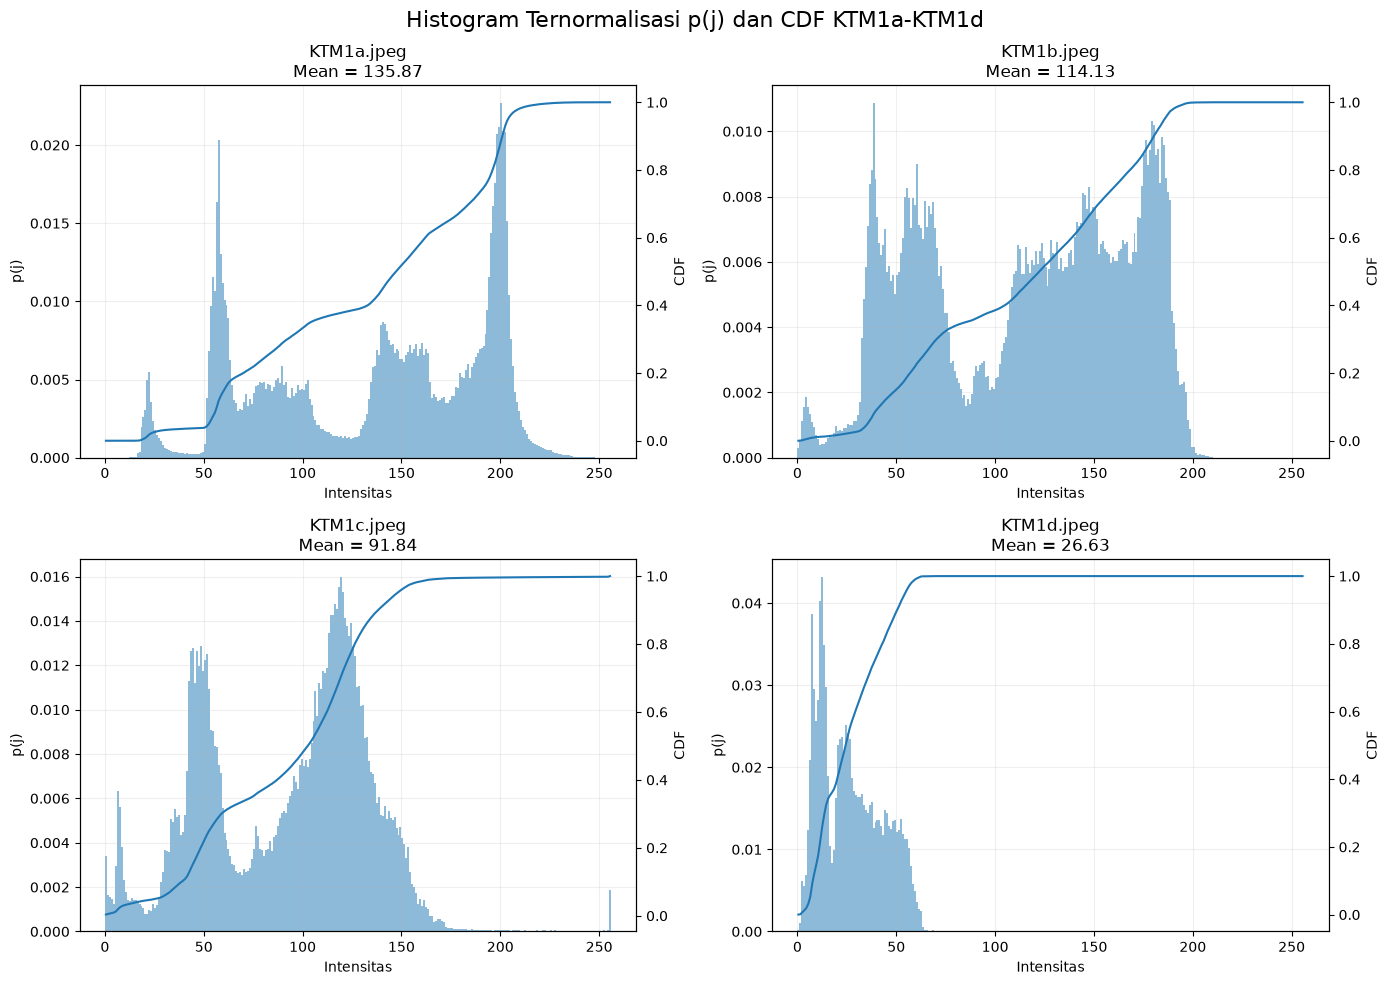

ANALISIS KECERAHAN CITRA
KTM1a.jpeg: mean intensitas = 135.87
KTM1b.jpeg: mean intensitas = 114.13
KTM1c.jpeg: mean intensitas = 91.84
KTM1d.jpeg: mean intensitas = 26.63

Citra paling gelap : KTM1d.jpeg
Citra paling terang: KTM1a.jpeg


In [198]:
# ============================================================
# NOMOR 2
# Histogram ternormalisasi dan CDF KTM1a - KTM1d
# dalam satu figure 2 x 2
# ============================================================

ktm_files = [
    'KTM1a.jpeg',
    'KTM1b.jpeg',
    'KTM1c.jpeg',
    'KTM1d.jpeg'
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10)
)

axes = axes.ravel()

mean_brightness = {}

for i, filename in enumerate(ktm_files):

    img = read_gray(filename)

    # Rata-rata intensitas untuk mengetahui
    # citra paling gelap dan paling terang
    mean_brightness[filename] = np.mean(img)

    hist, p, cdf, bin_edges = \
        normalized_histogram_and_cdf(img)

    # Titik tengah bin
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    ax = axes[i]

    # Histogram ternormalisasi
    ax.bar(
        bin_centers,
        p,
        width=1,
        alpha=0.5,
        label='p(j)'
    )

    # CDF
    ax2 = ax.twinx()

    ax2.plot(
        bin_centers,
        cdf,
        label='CDF'
    )

    ax.set_title(
        f'{filename}\nMean = {mean_brightness[filename]:.2f}'
    )

    ax.set_xlabel('Intensitas')
    ax.set_ylabel('p(j)')
    ax2.set_ylabel('CDF')

    ax.grid(alpha=0.2)

plt.suptitle(
    'Histogram Ternormalisasi p(j) dan CDF KTM1a-KTM1d',
    fontsize=16
)

plt.tight_layout()
plt.show()


# ============================================================
# MENENTUKAN CITRA PALING GELAP DAN PALING TERANG
# ============================================================

darkest = min(
    mean_brightness,
    key=mean_brightness.get
)

brightest = max(
    mean_brightness,
    key=mean_brightness.get
)

print("=" * 60)
print("ANALISIS KECERAHAN CITRA")
print("=" * 60)

for filename, mean in mean_brightness.items():
    print(f"{filename}: mean intensitas = {mean:.2f}")

print()
print("Citra paling gelap :", darkest)
print("Citra paling terang:", brightest)



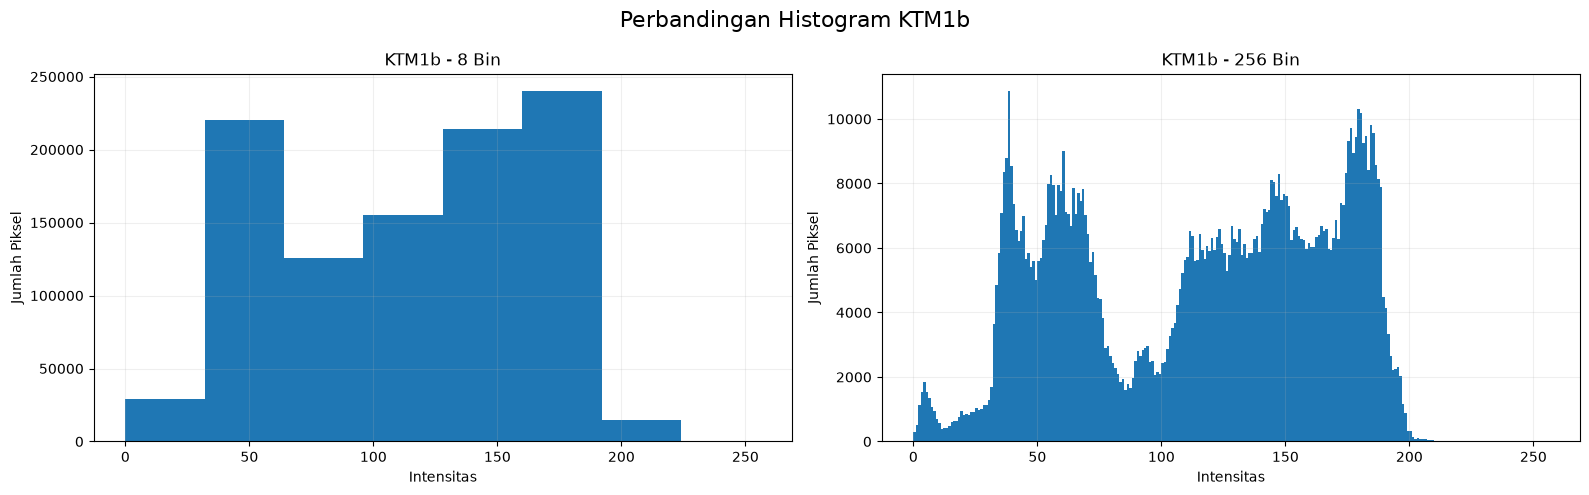

In [199]:
# ============================================================
# NOMOR 3
# KTM1b dengan PARAM['bins'] dan 256 bin
# ============================================================

img = read_gray('KTM1b.jpeg')

# ------------------------------------------------------------
# Histogram dengan jumlah bin sesuai PARAM
# ------------------------------------------------------------
hist_param, bins_param = np.histogram(
    img.ravel(),
    bins=PARAM['bins'],
    range=(0, 256)
)

# ------------------------------------------------------------
# Histogram dengan 256 bin
# ------------------------------------------------------------
hist_256, bins_256 = np.histogram(
    img.ravel(),
    bins=256,
    range=(0, 256)
)

# Titik tengah masing-masing bin
centers_param = (
    bins_param[:-1] + bins_param[1:]
) / 2

centers_256 = (
    bins_256[:-1] + bins_256[1:]
) / 2


# ------------------------------------------------------------
# Tampilkan berdampingan
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 5)
)

# Histogram PARAM['bins']
axes[0].bar(
    centers_param,
    hist_param,
    width=256 / PARAM['bins'],
    align='center'
)

axes[0].set_title(
    f'KTM1b - {PARAM["bins"]} Bin'
)

axes[0].set_xlabel('Intensitas')
axes[0].set_ylabel('Jumlah Piksel')
axes[0].grid(alpha=0.2)


# Histogram 256 bin
axes[1].bar(
    centers_256,
    hist_256,
    width=1
)

axes[1].set_title(
    'KTM1b - 256 Bin'
)

axes[1].set_xlabel('Intensitas')
axes[1].set_ylabel('Jumlah Piksel')
axes[1].grid(alpha=0.2)

plt.suptitle(
    'Perbandingan Histogram KTM1b',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [200]:
# ============================================================
# E-2 TAHAP 1
# HISTOGRAM EQUALIZATION - lena_lc.jpg
# ============================================================

lena_lc = cv.imread(
    LENA_LC,
    cv.IMREAD_GRAYSCALE
)

if lena_lc is None:
    raise FileNotFoundError(
        'lena_lc.jpg tidak ditemukan!'
    )

print('Ukuran lena_lc:', lena_lc.shape)

Ukuran lena_lc: (512, 512)


In [201]:
p_lena_lc = (
    hist_lena_lc /
    lena_lc.size
)

In [202]:
cdf_lena_lc = np.cumsum(
    p_lena_lc
)

In [203]:
L = 256

transform_lena_lc = np.round(
    (L - 1) * cdf_lena_lc
).astype(np.uint8)

In [204]:
lena_lc_equal_manual = (
    transform_lena_lc[lena_lc]
)

In [205]:
lena_lc_equal_cv = cv.equalizeHist(
    lena_lc
)

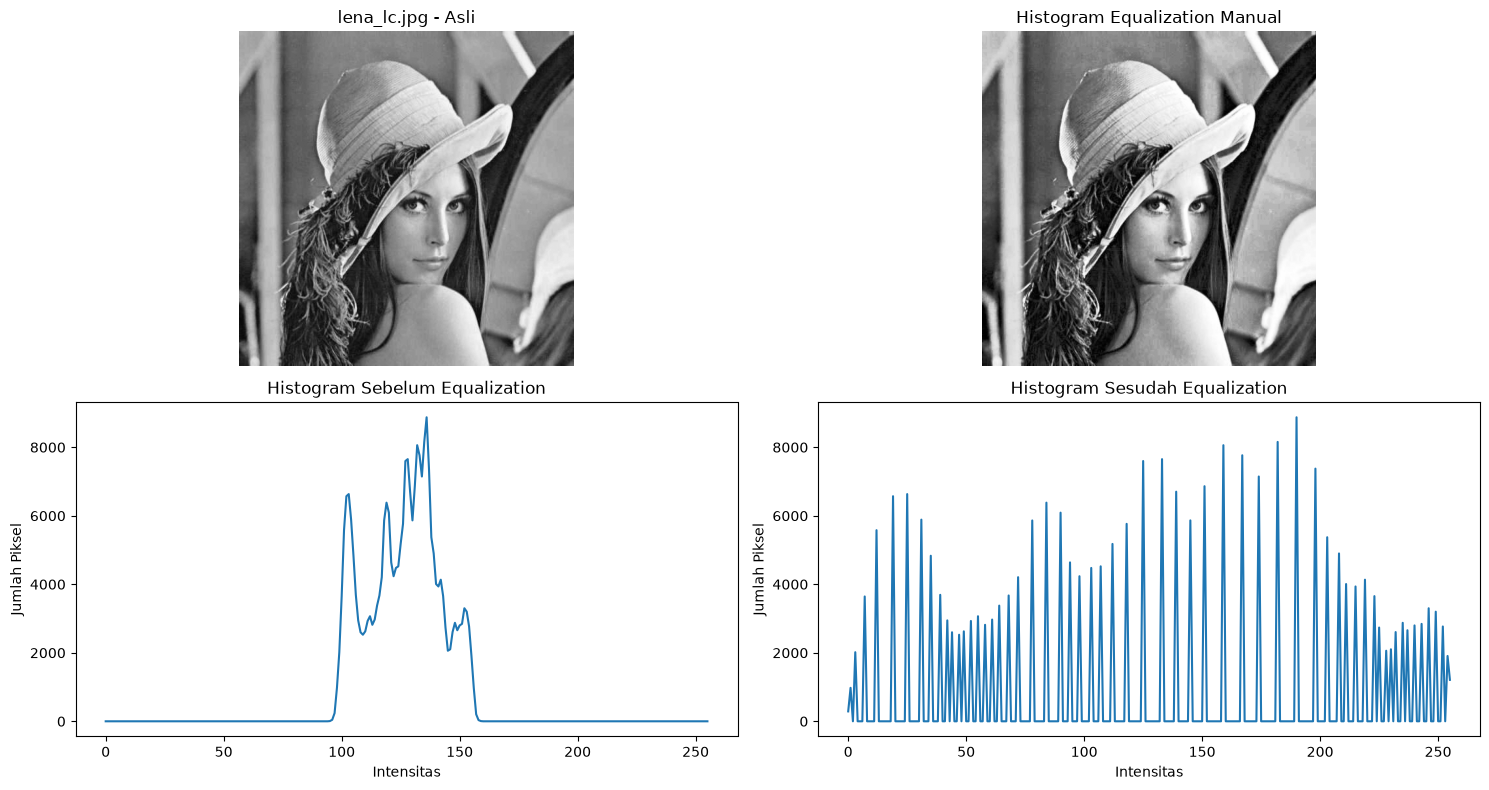

In [206]:
plt.figure(figsize=(15, 8))

# ------------------------------------------------------------
# Citra asli
# ------------------------------------------------------------
plt.subplot(2, 2, 1)

plt.imshow(
    lena_lc,
    cmap='gray'
)

plt.title(
    'lena_lc.jpg - Asli'
)

plt.axis('off')


# ------------------------------------------------------------
# Histogram Equalization manual
# ------------------------------------------------------------
plt.subplot(2, 2, 2)

plt.imshow(
    lena_lc_equal_manual,
    cmap='gray'
)

plt.title(
    'Histogram Equalization Manual'
)

plt.axis('off')


# ------------------------------------------------------------
# Histogram asli
# ------------------------------------------------------------
plt.subplot(2, 2, 3)

plt.plot(
    hist_lena_lc
)

plt.title(
    'Histogram Sebelum Equalization'
)

plt.xlabel('Intensitas')
plt.ylabel('Jumlah Piksel')


# ------------------------------------------------------------
# Histogram hasil
# ------------------------------------------------------------
plt.subplot(2, 2, 4)

hist_lena_lc_equal = histogram_manual(
    lena_lc_equal_manual
)

plt.plot(
    hist_lena_lc_equal
)

plt.title(
    'Histogram Sesudah Equalization'
)

plt.xlabel('Intensitas')
plt.ylabel('Jumlah Piksel')

plt.tight_layout()
plt.show()

In [207]:
selisih_lena_lc = np.max(
    np.abs(
        lena_lc_equal_manual.astype(np.int16)
        -
        lena_lc_equal_cv.astype(np.int16)
    )
)

print(
    'Selisih maksimum Manual vs OpenCV:',
    selisih_lena_lc
)

Selisih maksimum Manual vs OpenCV: 0


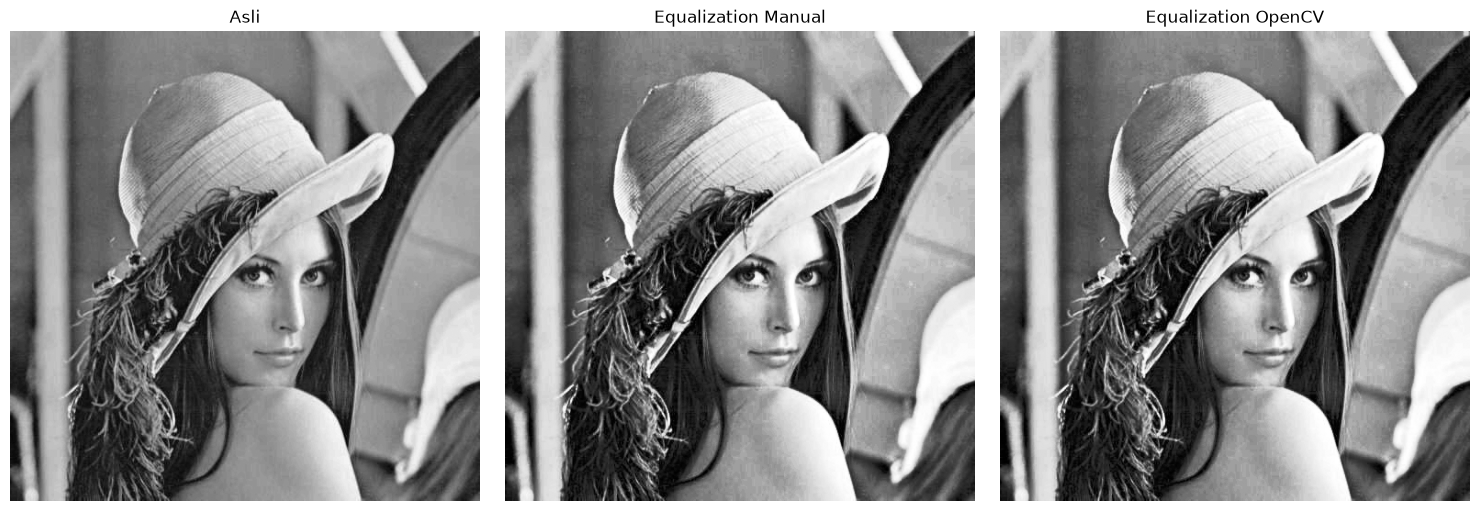

In [208]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)

plt.imshow(
    lena_lc,
    cmap='gray'
)

plt.title('Asli')
plt.axis('off')


plt.subplot(1, 3, 2)

plt.imshow(
    lena_lc_equal_manual,
    cmap='gray'
)

plt.title('Equalization Manual')
plt.axis('off')


plt.subplot(1, 3, 3)

plt.imshow(
    lena_lc_equal_cv,
    cmap='gray'
)

plt.title('Equalization OpenCV')
plt.axis('off')

plt.tight_layout()
plt.show()

In [209]:
selisih = np.max(
    np.abs(
        lena_lc_equal_manual.astype(np.int16)
        -
        lena_lc_equal_cv.astype(np.int16)
    )
)

print(
    'Selisih maksimum Manual vs OpenCV:',
    selisih
)

Selisih maksimum Manual vs OpenCV: 0


In [210]:
# ============================================================
# E-2.1 TAHAP 2
# Histogram Equalization pada KTM1a.jpg
# ============================================================

ktm1a = cv.imread(
    KTM1A,
    cv.IMREAD_GRAYSCALE
)

if ktm1a is None:
    raise FileNotFoundError(
        f'{KTM1A} tidak ditemukan'
    )

print('Ukuran KTM1a:', ktm1a.shape)

Ukuran KTM1a: (1280, 789)


In [211]:
hist_ktm = histogram_manual(ktm1a)

p_ktm = hist_ktm / ktm1a.size

cdf_ktm = np.cumsum(p_ktm)

L = 256

transform_ktm = np.round(
    (L - 1) * cdf_ktm
).astype(np.uint8)

ktm1a_equal_manual = transform_ktm[ktm1a]

ktm1a_equal_cv = cv.equalizeHist(
    ktm1a
)

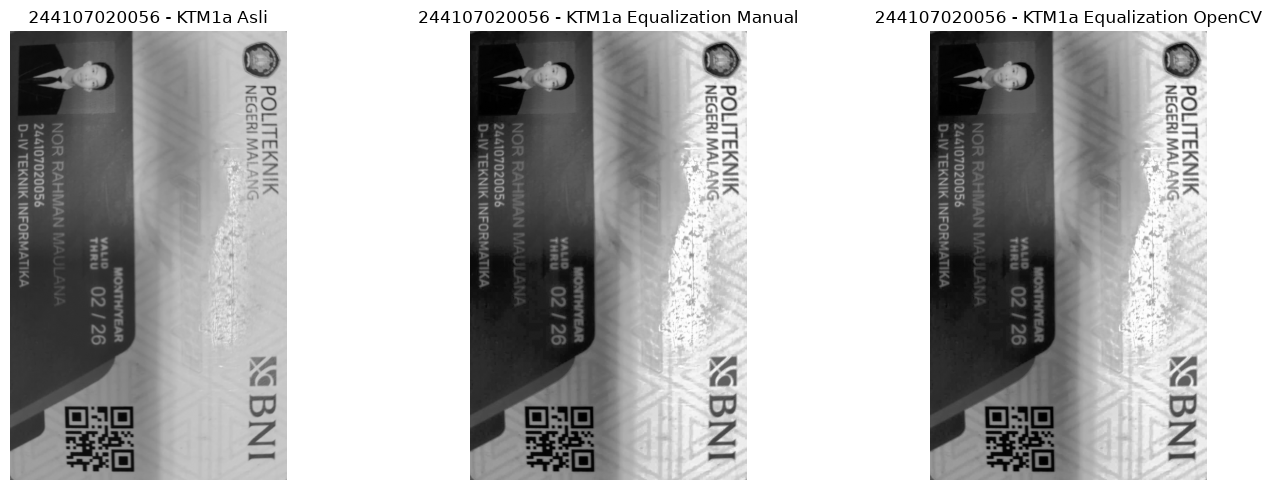

In [212]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)

plt.imshow(
    ktm1a,
    cmap='gray'
)

plt.title(
    NIM + ' - KTM1a Asli'
)

plt.axis('off')


plt.subplot(1, 3, 2)

plt.imshow(
    ktm1a_equal_manual,
    cmap='gray'
)

plt.title(
    NIM + ' - KTM1a Equalization Manual'
)

plt.axis('off')


plt.subplot(1, 3, 3)

plt.imshow(
    ktm1a_equal_cv,
    cmap='gray'
)

plt.title(
    NIM + ' - KTM1a Equalization OpenCV'
)

plt.axis('off')

plt.tight_layout()
plt.show()

In [213]:
selisih_ktm = np.max(
    np.abs(
        ktm1a_equal_manual.astype(np.int16)
        -
        ktm1a_equal_cv.astype(np.int16)
    )
)

print(
    'Selisih maksimum KTM1a:',
    selisih_ktm
)

Selisih maksimum KTM1a: 0


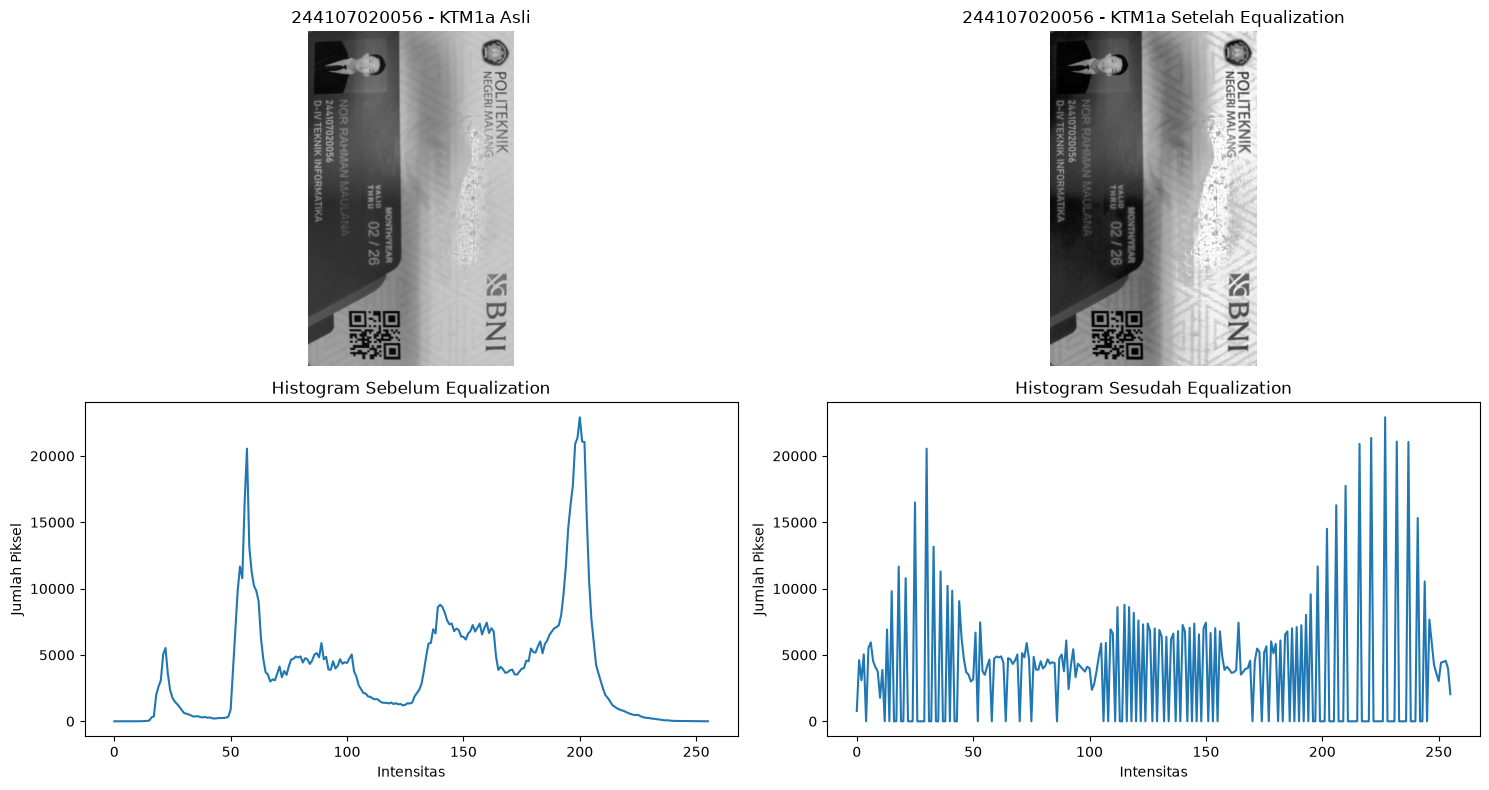

In [214]:
hist_sebelum = histogram_manual(ktm1a)

hist_sesudah = histogram_manual(
    ktm1a_equal_cv
)

plt.figure(figsize=(15, 8))

# Citra asli
plt.subplot(2, 2, 1)

plt.imshow(
    ktm1a,
    cmap='gray'
)

plt.title(
    NIM + ' - KTM1a Asli'
)

plt.axis('off')


# Citra hasil
plt.subplot(2, 2, 2)

plt.imshow(
    ktm1a_equal_cv,
    cmap='gray'
)

plt.title(
    NIM + ' - KTM1a Setelah Equalization'
)

plt.axis('off')


# Histogram asli
plt.subplot(2, 2, 3)

plt.plot(
    hist_sebelum
)

plt.title('Histogram Sebelum Equalization')

plt.xlabel('Intensitas')
plt.ylabel('Jumlah Piksel')


# Histogram hasil
plt.subplot(2, 2, 4)

plt.plot(
    hist_sesudah
)

plt.title('Histogram Sesudah Equalization')

plt.xlabel('Intensitas')
plt.ylabel('Jumlah Piksel')

plt.tight_layout()
plt.show()

In [215]:
psnr = cv.PSNR(
    ktm1a,
    ktm1a_equal_cv
)

print(
    'PSNR KTM1a sebelum vs sesudah equalization:',
    psnr,
    'dB'
)

PSNR KTM1a sebelum vs sesudah equalization: 21.28825942303297 dB


a. Terapkan ekualisasi manual dan cv.equalizeHist pada KTM1a.jpg versi grayscale

In [216]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Baca KTM1a sebagai grayscale
ktm1a = cv.imread(
    'KTM1a.jpeg',
    cv.IMREAD_GRAYSCALE
)

if ktm1a is None:
    raise FileNotFoundError('KTM1a.jpeg tidak ditemukan')

print('Ukuran KTM1a:', ktm1a.shape)

Ukuran KTM1a: (1280, 789)


In [217]:
def histogram_manual(img, L=256):

    hist = np.zeros(L, dtype=np.int64)

    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            hist[img[y, x]] += 1

    return hist

In [218]:
hist = histogram_manual(ktm1a)

# Normalisasi histogram
p = hist / ktm1a.size

# CDF
cdf = np.cumsum(p)

In [219]:
L = 256

transform = np.round(
    (L - 1) * cdf
).astype(np.uint8)

ktm1a_manual = transform[ktm1a]

In [220]:

ktm1a_cv = cv.equalizeHist(ktm1a)

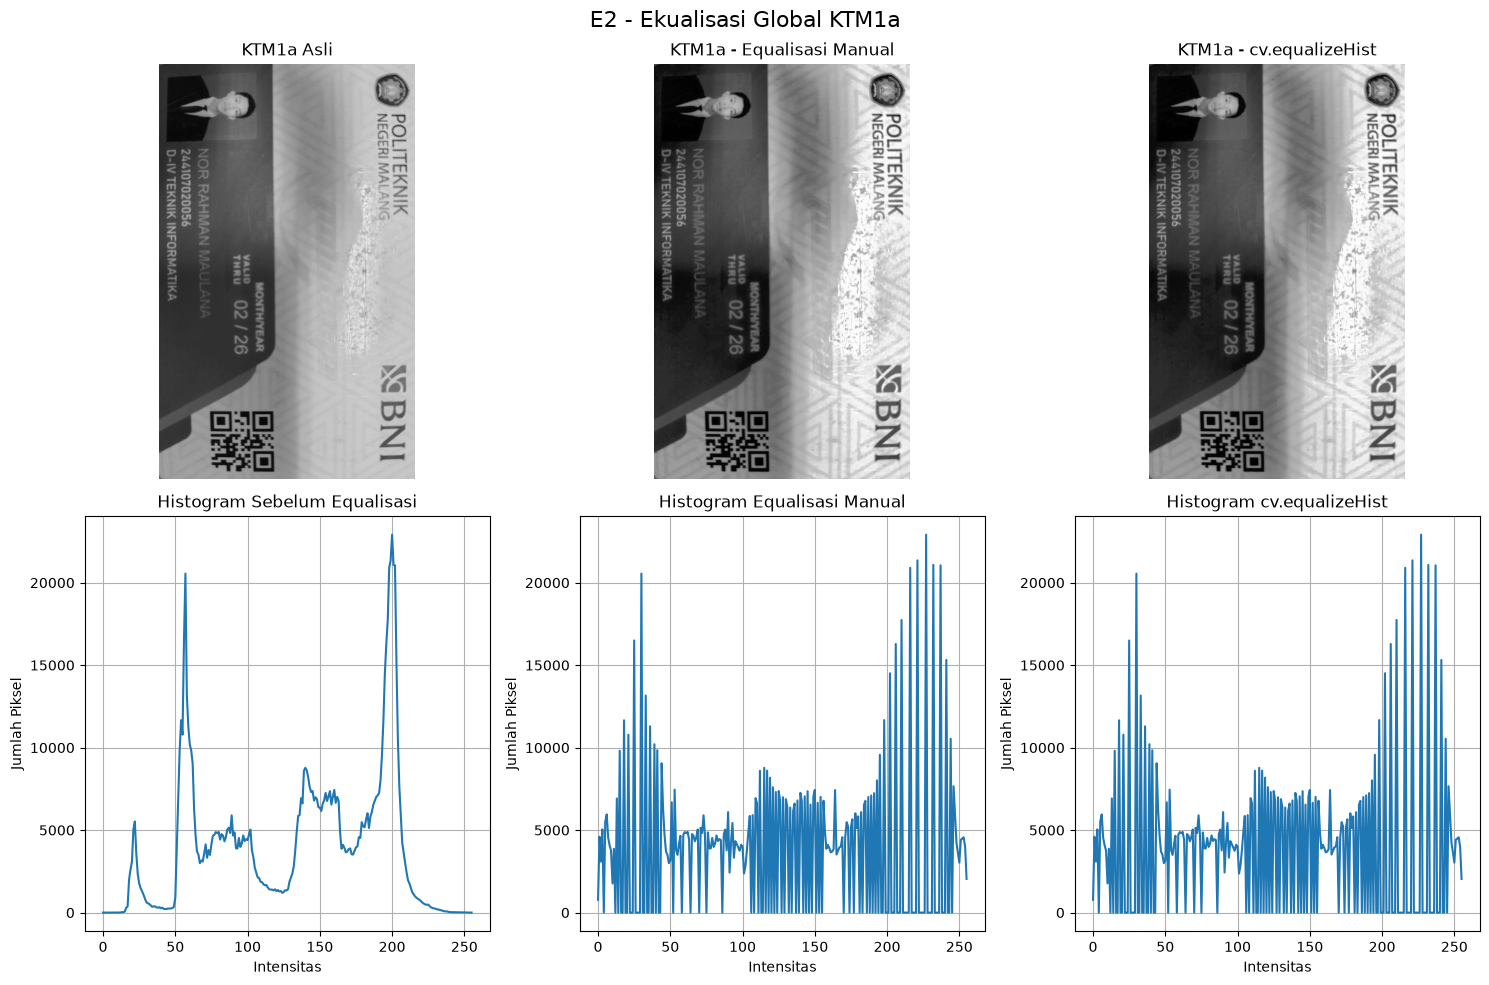

In [221]:
# Histogram sebelum
hist_before = histogram_manual(ktm1a)

# Histogram hasil manual
hist_manual_after = histogram_manual(ktm1a_manual)

# Histogram hasil OpenCV
hist_cv_after = histogram_manual(ktm1a_cv)


plt.figure(figsize=(15, 10))

# ============================================================
# CITRA ASLI
# ============================================================
plt.subplot(2, 3, 1)

plt.imshow(
    ktm1a,
    cmap='gray'
)

plt.title('KTM1a Asli')
plt.axis('off')


# ============================================================
# HASIL MANUAL
# ============================================================
plt.subplot(2, 3, 2)

plt.imshow(
    ktm1a_manual,
    cmap='gray'
)

plt.title('KTM1a - Equalisasi Manual')
plt.axis('off')


# ============================================================
# HASIL OPENCV
# ============================================================
plt.subplot(2, 3, 3)

plt.imshow(
    ktm1a_cv,
    cmap='gray'
)

plt.title('KTM1a - cv.equalizeHist')
plt.axis('off')


# ============================================================
# HISTOGRAM ASLI
# ============================================================
plt.subplot(2, 3, 4)

plt.plot(hist_before)

plt.title('Histogram Sebelum Equalisasi')
plt.xlabel('Intensitas')
plt.ylabel('Jumlah Piksel')
plt.grid()


# ============================================================
# HISTOGRAM MANUAL
# ============================================================
plt.subplot(2, 3, 5)

plt.plot(hist_manual_after)

plt.title('Histogram Equalisasi Manual')
plt.xlabel('Intensitas')
plt.ylabel('Jumlah Piksel')
plt.grid()


# ============================================================
# HISTOGRAM OPENCV
# ============================================================
plt.subplot(2, 3, 6)

plt.plot(hist_cv_after)

plt.title('Histogram cv.equalizeHist')
plt.xlabel('Intensitas')
plt.ylabel('Jumlah Piksel')
plt.grid()


plt.suptitle(
    'E2 - Ekualisasi Global KTM1a',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [222]:

# ------------------------------------------------------------
# Hitung PNSR
# ------------------------------------------------------------

psnr_manual = cv.PSNR(
    ktm1a,
    ktm1a_manual
)

psnr_cv = cv.PSNR(
    ktm1a,
    ktm1a_cv
)

print('PSNR Manual :', psnr_manual, 'dB')
print('PSNR OpenCV :', psnr_cv, 'dB')

PSNR Manual : 21.28825942303297 dB
PSNR OpenCV : 21.28825942303297 dB


2. Ekualisasi lokal dengan CLAHE pada KTM1a

In [223]:
print(PARAM)

{'bins': 8, 'clip': 1.5, 'tile': 2, 'L': 8}


In [224]:
# ============================================================
# CLAHE
# ============================================================

clahe = cv.createCLAHE(
    clipLimit=PARAM['clip'],
    tileGridSize=(
        PARAM['tile'],
        PARAM['tile']
    )
)

ktm1a_clahe = clahe.apply(ktm1a)

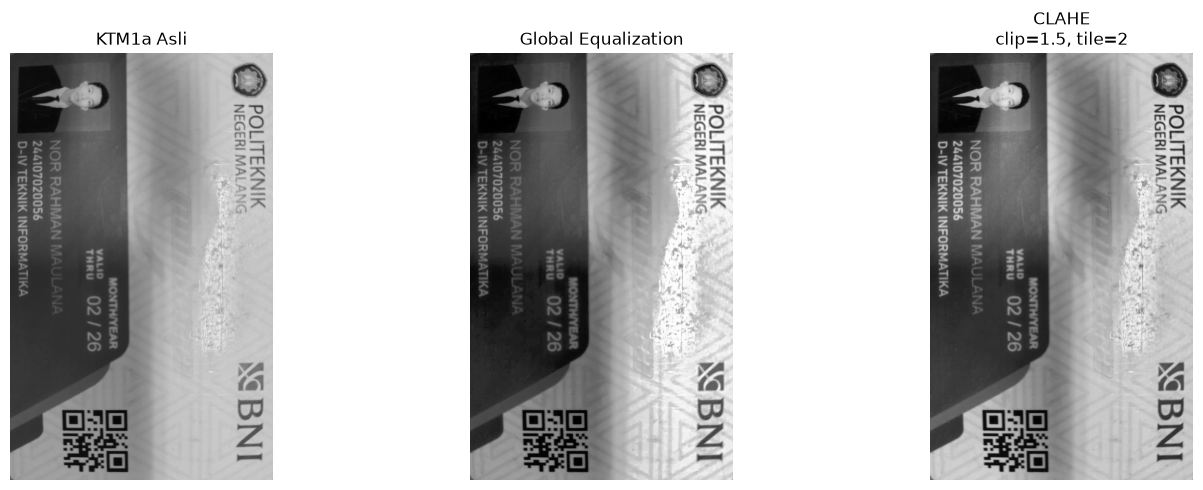

In [232]:
plt.figure(figsize=(15, 5))

# Asli
plt.subplot(1, 3, 1)

plt.imshow(
    ktm1a,
    cmap='gray'
)

plt.title('KTM1a Asli')
plt.axis('off')


# Global
plt.subplot(1, 3, 2)

plt.imshow(
    ktm1a_cv,
    cmap='gray'
)

plt.title('Global Equalization')
plt.axis('off')


# CLAHE
plt.subplot(1, 3, 3)

plt.imshow(
    ktm1a_clahe,
    cmap='gray'
)

plt.title(
    f'CLAHE\nclip={PARAM["clip"]}, '
    f'tile={PARAM["tile"]}'
)

plt.axis('off')


plt.tight_layout()
plt.show()

Coba tiga nilai clipLimit

In [233]:
PARAM['clip']

1.5

In [234]:
clip_values = [
    max(0.1, PARAM['clip'] - 1.0),
    max(0.1, PARAM['clip'] - 0.5),
    PARAM['clip'],
    PARAM['clip'] + 0.5,
    PARAM['clip'] + 1.0
]

print('Nilai clipLimit yang dicoba:')
print(clip_values)

Nilai clipLimit yang dicoba:
[0.5, 1.0, 1.5, 2.0, 2.5]


In [235]:
hasil_clahe = []

for clip in clip_values:

    clahe_test = cv.createCLAHE(
        clipLimit=clip,
        tileGridSize=(
            PARAM['tile'],
            PARAM['tile']
        )
    )

    hasil = clahe_test.apply(ktm1a)

    hasil_clahe.append(hasil)

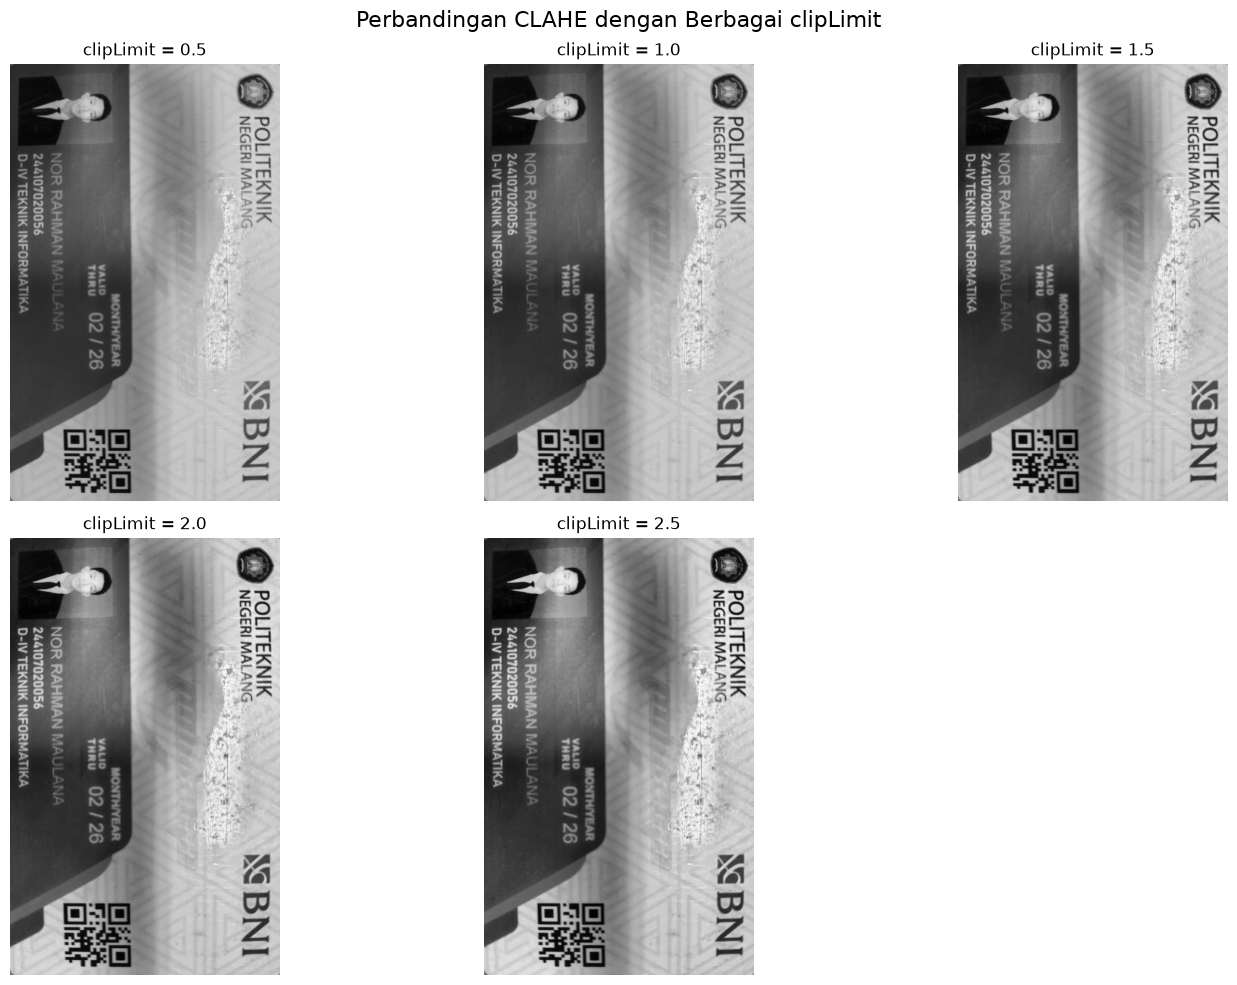

In [236]:
plt.figure(figsize=(15, 10))

for i in range(len(clip_values)):

    plt.subplot(2, 3, i + 1)

    plt.imshow(
        hasil_clahe[i],
        cmap='gray'
    )

    plt.title(
        f'clipLimit = {clip_values[i]}'
    )

    plt.axis('off')

plt.suptitle(
    'Perbandingan CLAHE dengan Berbagai clipLimit',
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:

# ============================================================
# E-3.1 — Floyd-Steinberg
# ============================================================

#Buat fungsi Floyd-Steinberg

def floyd_steinberg(gray, L=2):

    # Ubah ke float agar error dapat disebarkan
    img = gray.astype(np.float32).copy()

    # Jarak antar level
    step = 255.0 / (L - 1)

    H, W = img.shape

    # Proses dari kiri ke kanan,
    # kemudian dari atas ke bawah
    for y in range(H):
        for x in range(W):

            # Nilai piksel sebelum kuantisasi
            lama = img[y, x]

            # Cari level terdekat
            baru = np.round(
                lama / step
            ) * step

            # Simpan nilai baru
            img[y, x] = baru

            # Hitung error
            error = lama - baru

            # Sebarkan error ke kanan
            if x + 1 < W:
                img[y, x + 1] += error * 7 / 16

            # Sebarkan error ke kiri-bawah
            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += error * 3 / 16

            # Sebarkan error ke bawah
            if y + 1 < H:
                img[y + 1, x] += error * 5 / 16

            # Sebarkan error ke kanan-bawah
            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += error * 1 / 16

    # Pastikan nilai tetap 0-255
    return np.clip(
        img,
        0,
        255
    ).astype(np.uint8)

In [241]:

# ============================================================
# Langkah 2 — Tahap 1: lena.jpg
# ============================================================

lena = cv.imread(
    'Lenna.png'
)

if lena is None:
    raise FileNotFoundError(
        'Lenna.jpeg tidak ditemukan'
    )

print('Ukuran lena:', lena.shape)


Ukuran lena: (512, 512, 3)


In [242]:
# Pisahkan kanal B, G, R
b, g, r = cv.split(lena)

# Dithering masing-masing kanal
b_dither = floyd_steinberg(b, L=2)
g_dither = floyd_steinberg(g, L=2)
r_dither = floyd_steinberg(r, L=2)

# Gabungkan kembali
lena_dither = cv.merge([
    b_dither,
    g_dither,
    r_dither
])

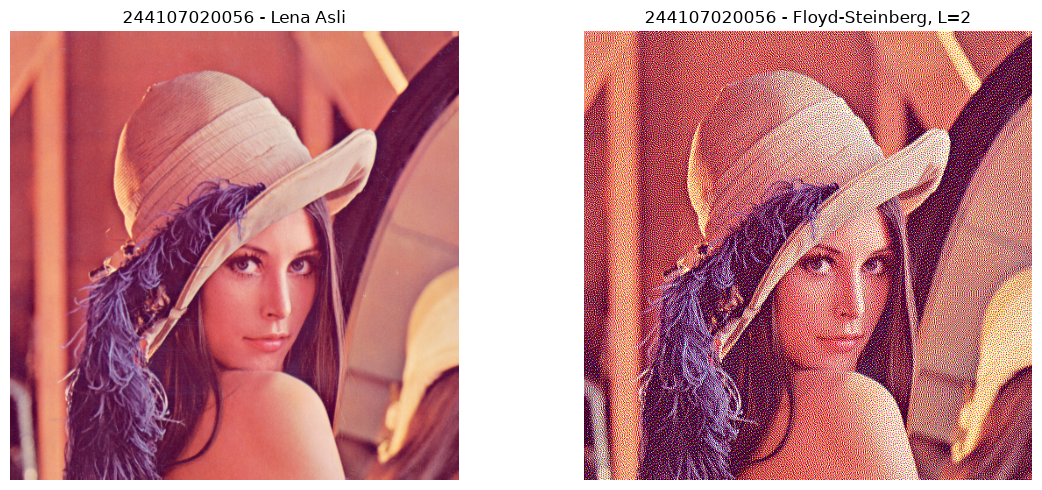

In [243]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.imshow(
    cv.cvtColor(
        lena,
        cv.COLOR_BGR2RGB
    )
)

plt.title(
    NIM + ' - Lena Asli'
)

plt.axis('off')


plt.subplot(1, 2, 2)

plt.imshow(
    cv.cvtColor(
        lena_dither,
        cv.COLOR_BGR2RGB
    )
)

plt.title(
    NIM + ' - Floyd-Steinberg, L=2'
)

plt.axis('off')


plt.tight_layout()
plt.show()

In [ ]:

# ============================================================
# E-3.1 — Floyd-Steinberg
# ============================================================

In [244]:
PARAM['L'] = 8

In [245]:
# ============================================================
# TAHAP 2 - KTM1b
# ============================================================

ktm1b = cv.imread(
    'KTM1b.jpeg'
)

if ktm1b is None:
    raise FileNotFoundError(
        'KTM1b.jpeg tidak ditemukan'
    )

print('Ukuran KTM1b:', ktm1b.shape)
print('Jumlah level L:', PARAM['L'])

Ukuran KTM1b: (1280, 781, 3)
Jumlah level L: 8


In [246]:
# Pisahkan kanal
b, g, r = cv.split(ktm1b)

# Dithering dengan L dari NIM
b_dither = floyd_steinberg(
    b,
    L=PARAM['L']
)

g_dither = floyd_steinberg(
    g,
    L=PARAM['L']
)

r_dither = floyd_steinberg(
    r,
    L=PARAM['L']
)

# Gabungkan
ktm1b_dither = cv.merge([
    b_dither,
    g_dither,
    r_dither
])

In [ ]:
# ============================================================
# E-3.1 — Floyd-Steinberg
# ============================================================

In [248]:
# ============================================================
# E-3.2 TAHAP 1
# lena_lc.jpg
# ============================================================

lena_lc = cv.imread(
    'lena_lc.jpeg',
    cv.IMREAD_GRAYSCALE
)

if lena_lc is None:
    raise FileNotFoundError(
        'lena_lc.jpg tidak ditemukan'
    )

In [249]:
lena_eq = cv.equalizeHist(
    lena_lc
)

In [250]:
lena_eq_dither = floyd_steinberg(
    lena_eq,
    L=2
)

In [251]:
lena_direct_dither = floyd_steinberg(
    lena_lc,
    L=2
)

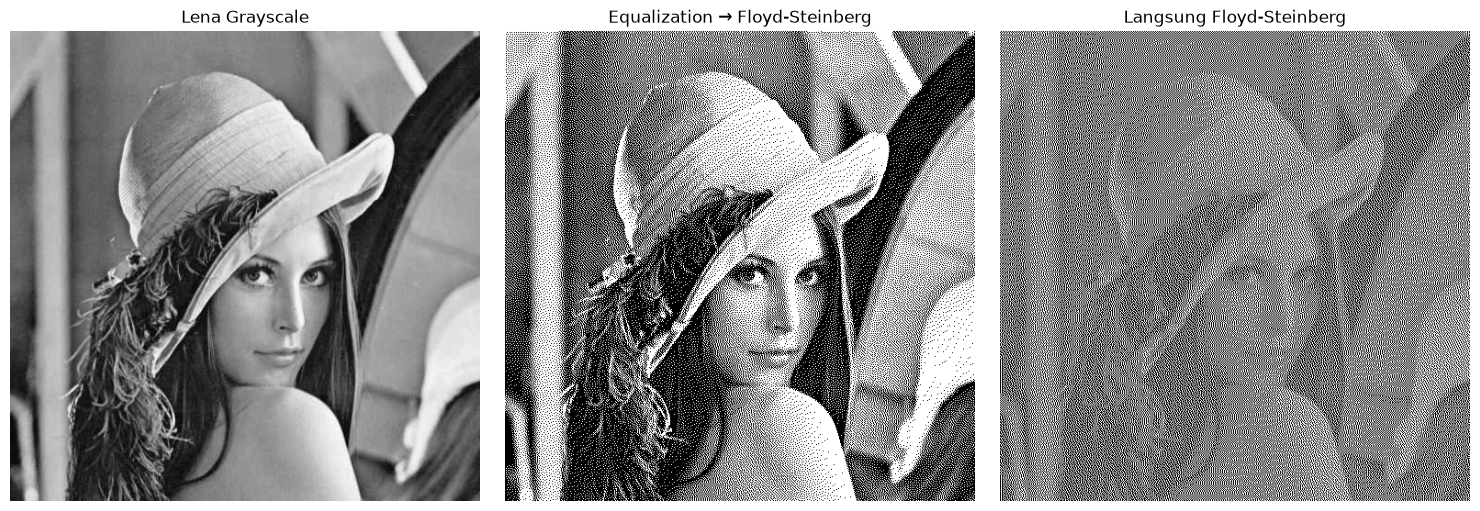

In [252]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)

plt.imshow(
    lena_lc,
    cmap='gray'
)

plt.title('Lena Grayscale')
plt.axis('off')


plt.subplot(1, 3, 2)

plt.imshow(
    lena_eq_dither,
    cmap='gray'
)

plt.title(
    'Equalization → Floyd-Steinberg'
)

plt.axis('off')


plt.subplot(1, 3, 3)

plt.imshow(
    lena_direct_dither,
    cmap='gray'
)

plt.title(
    'Langsung Floyd-Steinberg'
)

plt.axis('off')


plt.tight_layout()
plt.show()

In [254]:
ktm1a_gray = cv.imread(
    'KTM1a.jpeg',
    cv.IMREAD_GRAYSCALE
)

if ktm1a_gray is None:
    raise FileNotFoundError(
        'KTM1a.jpg tidak ditemukan'
    )

In [255]:
ktm1a_eq = cv.equalizeHist(
    ktm1a_gray
)

ktm1a_eq_dither = floyd_steinberg(
    ktm1a_eq,
    L=PARAM['L']
)

In [256]:
ktm1a_direct_dither = floyd_steinberg(
    ktm1a_gray,
    L=PARAM['L']
)

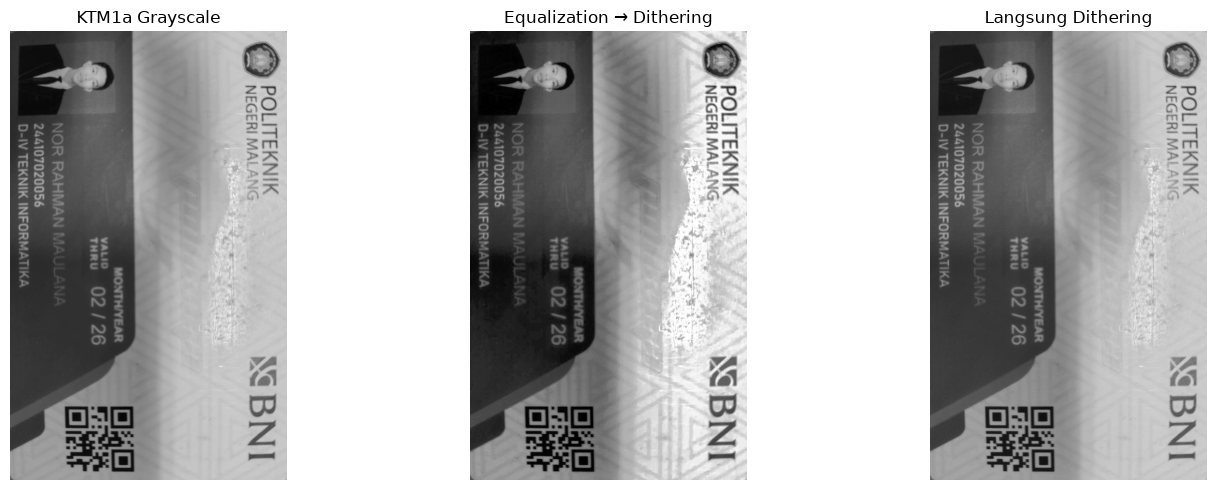

In [257]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)

plt.imshow(
    ktm1a_gray,
    cmap='gray'
)

plt.title('KTM1a Grayscale')
plt.axis('off')


plt.subplot(1, 3, 2)

plt.imshow(
    ktm1a_eq_dither,
    cmap='gray'
)

plt.title(
    'Equalization → Dithering'
)

plt.axis('off')


plt.subplot(1, 3, 3)

plt.imshow(
    ktm1a_direct_dither,
    cmap='gray'
)

plt.title(
    'Langsung Dithering'
)

plt.axis('off')


plt.tight_layout()
plt.show()

E-3 Jawaban Tugas Praktikum Dithering

==1a. Lena — sebelum dan sesudah dithering==
1. Pada percobaan ini dilakukan proses dithering Floyd-Steinberg pada citra lena.jpg dengan jumlah level L=2. Proses dilakukan dengan mengubah nilai piksel ke level intensitas terdekat, kemudian error hasil kuantisasi disebarkan ke piksel tetangga menggunakan bobot Floyd-Steinberg, yaitu 7/16 ke kanan, 3/16 ke kiri bawah, 5/16 ke bawah, dan 1/16 ke kanan bawah. Hasil dithering menunjukkan bahwa citra mengalami penyederhanaan jumlah level intensitas, tetapi detail dan bentuk objek masih dapat dipertahankan melalui pola distribusi piksel.

==1b. KTM1b — sebelum dan sesudah dithering==
Pada percobaan berikutnya, metode Floyd-Steinberg diterapkan pada citra KTM1b.jpg menggunakan jumlah level kuantisasi L yang diperoleh dari parameter NIM. Proses ini bertujuan mengurangi jumlah level intensitas dengan mendistribusikan error kuantisasi ke piksel tetangga yang belum diproses. Hasilnya kemudian dibandingkan dengan citra KTM1b sebelum dithering untuk melihat perubahan tampilan dan keterjagaan detail pada kartu.
Pada citra KTM1b digunakan L=8 sesuai parameter NIM.

2. Lena — Equalization kemudian Dithering
Pada percobaan ini citra lena_lc.jpg terlebih dahulu diubah menjadi grayscale, kemudian dilakukan histogram equalization untuk memperbaiki penyebaran intensitas piksel. Setelah itu, citra hasil equalization diproses menggunakan dithering Floyd-Steinberg. Tahapan ini digunakan untuk melihat pengaruh perbaikan distribusi intensitas sebelum dilakukan proses dithering.
2b. Lena — Dithering langsung
Sebagai pembanding, dithering Floyd-Steinberg juga diterapkan langsung pada citra lena_lc.jpg tanpa melalui histogram equalization. Hasil ini digunakan sebagai pembanding untuk mengetahui pengaruh histogram equalization terhadap hasil akhir dithering.

2c. KTM1a — Equalization → Dithering
Pada citra KTM1a.jpg, citra terlebih dahulu diubah menjadi grayscale. Selanjutnya dilakukan histogram equalization untuk memperbaiki distribusi intensitas pada citra. Citra hasil equalization kemudian diproses menggunakan dithering Floyd-Steinberg dengan jumlah level L sesuai parameter NIM. Tahapan ini bertujuan untuk melihat apakah perbaikan distribusi intensitas sebelum dithering dapat membantu mempertahankan atau meningkatkan keterbacaan informasi pada KTM.

2d. KTM1a — Dithering langsung
Sebagai pembanding, citra KTM1a.jpg grayscale langsung diproses menggunakan dithering Floyd-Steinberg tanpa melalui histogram equalization. Hasilnya dibandingkan dengan metode equalization yang dilanjutkan dithering untuk melihat perbedaan keterbacaan teks pada KTM.

2e. Kesimpulan perbandingan
Berdasarkan perbandingan kedua metode, proses [pilih sesuai hasil gambar] menghasilkan teks pada KTM yang lebih terbaca dibandingkan metode lainnya. Histogram equalization terlebih dahulu memperbaiki distribusi intensitas citra, kemudian dithering Floyd-Steinberg menyederhanakan level intensitas dengan menyebarkan error ke piksel tetangga. Sementara itu, dithering langsung tidak melalui tahap perbaikan distribusi intensitas sehingga karakteristik intensitas awal citra tetap digunakan dalam proses dithering.